In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn import model_selection
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('../data/raw/transactions.csv')

## **Data Exploration:**


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  str    
 7   bin_country              299695 non-null  str    
 8   channel                  299695 non-null  str    
 9   merchant_category        299695 non-null  str    
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  transaction_tim

In [4]:
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0


In [5]:
# Strip whitespace from column names
df.columns = df.columns.str.strip()

In [6]:
df.describe()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,is_fraud
count,299695.0000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000,299695.000000
mean,149848.0000,3002.559432,973.397871,50.673321,148.142973,177.165279,0.153640,0.837999,0.872110,0.784588,357.049028,0.022062
std,86514.6388,1732.309663,525.241409,5.976391,200.364624,306.926507,0.360603,0.368453,0.333968,0.411109,427.672074,0.146887
min,1.0000,1.000000,1.000000,40.000000,3.520000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,74924.5000,1501.000000,516.000000,46.000000,46.190000,42.100000,0.000000,1.000000,1.000000,1.000000,136.600000,0.000000
50%,149848.0000,3007.000000,975.000000,51.000000,90.130000,89.990000,0.000000,1.000000,1.000000,1.000000,273.020000,0.000000
75%,224771.5000,4504.000000,1425.000000,56.000000,173.450000,191.110000,0.000000,1.000000,1.000000,1.000000,409.180000,0.000000
max,299695.0000,6000.000000,1890.000000,60.000000,4565.290000,16994.740000,1.000000,1.000000,1.000000,1.000000,3748.560000,1.000000


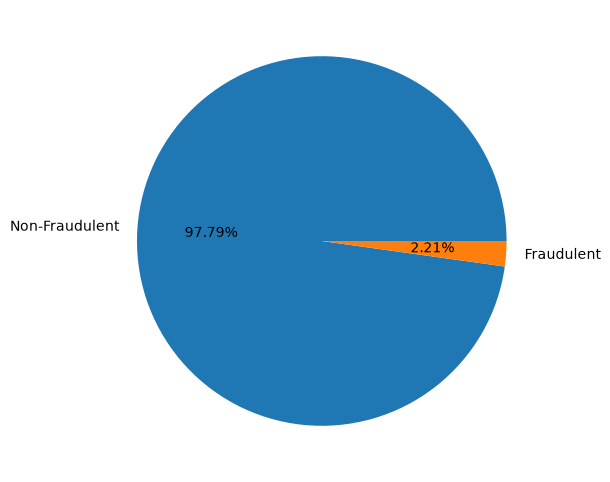

In [7]:
# Plot a pie chart of the `Status` feature
plt.figure(figsize=(6, 6))

labels = df['is_fraud'].value_counts().index
sizes = df['is_fraud'].value_counts().values
plt.pie(sizes, labels=['Non-Fraudulent', 'Fraudulent'], autopct='%1.2f%%')
plt.show()

## **Data Cleaning And Validation:**

In [8]:
df['is_fraud'] = df['is_fraud'].astype(bool)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  str    
 7   bin_country              299695 non-null  str    
 8   channel                  299695 non-null  str    
 9   merchant_category        299695 non-null  str    
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  transaction_tim

In [9]:
# Convert transaction_time to datetime and extract features
df['transaction_time'] = pd.to_datetime(df['transaction_time'])
df['transaction_hour'] = df['transaction_time'].dt.hour
df['transaction_day'] = df['transaction_time'].dt.dayofweek
df['transaction_month'] = df['transaction_time'].dt.month
df['is_weekend'] = (df['transaction_time'].dt.dayofweek >= 5).astype(int)

/tmp/ipykernel_105202/2786608654.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['transaction_day'] = df['transaction_time'].dt.dayofweek
/tmp/ipykernel_105202/2786608654.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['is_weekend'] = (df['transaction_time'].dt.dayofweek >= 5).astype(int)


In [10]:
# Create country mismatch feature
df['country_mismatch'] = (df['country'] != df['bin_country']).astype(int)

# Create transaction amount ratios
df['amount_vs_avg'] = df['amount'] / (df['avg_amount_user'] + 1e-8)

# Create time since first transaction
df['days_since_first'] = df.groupby('user_id')['transaction_time'].transform(
    lambda x: (x - x.min()).dt.total_seconds() / (24 * 3600)
)

# Drop unnecessary columns
columns_to_drop = ['transaction_id', 'transaction_time']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

print(f"Dataset shape: {df.shape}")

Dataset shape: (299695, 22)


## **Feature Engineering:**


In [11]:
# Simple one-hot encoding for categorical variables
categorical_cols = ['country', 'bin_country', 'channel', 'merchant_category', 'avs_match', 'cvv_result', 'three_ds_flag']

numerical_cols = ['account_age_days', 'total_transactions_user', 'avg_amount_user', 'amount', 'shipping_distance_km', 'transaction_hour', 'transaction_day', 'transaction_month', 'amount_vs_avg', 'days_since_first']

In [12]:
preprocessor = Pipeline([
    ('column_transformers', ColumnTransformer(
        transformers = [
            ('Encoder', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
            ('StandardScaler', StandardScaler(), numerical_cols)
        ]
    ))
])

In [13]:
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=df['is_fraud']
)

In [14]:
X_train_processed = preprocessor.fit_transform(X_train)
X_train_processed.shape

(239756, 43)

In [15]:
# The new Pipeline
preprocessor = Pipeline([
    ('column_transformers', ColumnTransformer(
        transformers = [
            ('Encoder', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
            ('StandardScaler', StandardScaler(), numerical_cols)
        ]
    ))
])

# **5- Model Training and testing**
In this last stage, I have applied the following actions:
* Perform cross validation to compare between three different models which are Logistic Regression, Decision Tree, and Stochastic Gradient Decent, and pick the one that performed the best.
* Fine-tune the hyperparameters of the best chosen model using also cross-validation.

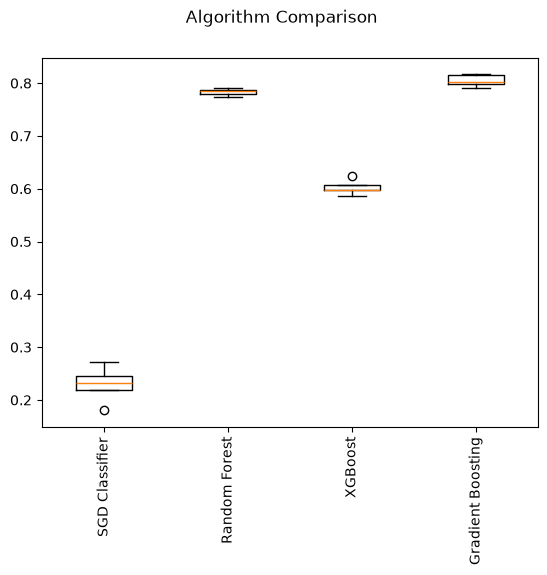

In [16]:
# preprocess the dataset
X_train_processed = preprocessor.fit_transform(X_train)

# prepare models
models = []
models.append(('SGD Classifier', SGDClassifier(loss="hinge", class_weight='balanced', random_state=42)))
models.append(('Random Forest', RandomForestClassifier(class_weight='balanced', n_jobs=-1)))
models.append(('XGBoost', XGBClassifier(tree_method="hist", scale_pos_weight=49)))
models.append(('Gradient Boosting', GradientBoostingClassifier( n_estimators=100, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42 )))


# evaluate each model in turn
results = []
names = []

scoring = 'f1'

for name, model in models:
	kfold = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
	cv_results = model_selection.cross_val_score(model, X_train_processed, y_train, cv=kfold, scoring=scoring, n_jobs=-1)
	results.append(cv_results)
	names.append(name)

# boxplot algorithm comparison
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
# rotate x-axis
plt.xticks(rotation=90)
plt.show()

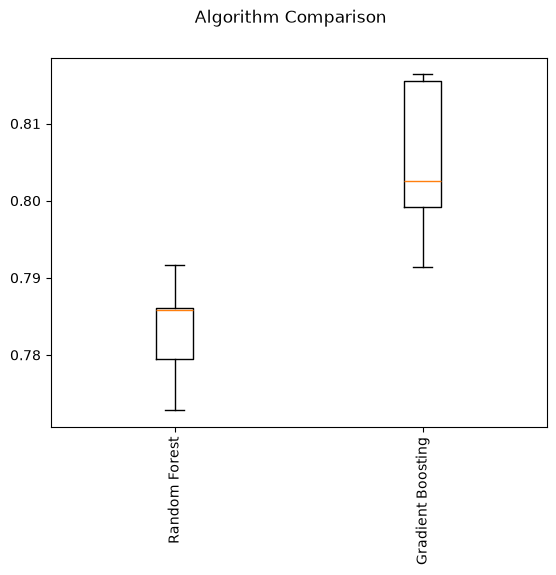

In [17]:
# boxplot algorithm comparison
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot([results[1], results[-1]])
ax.set_xticklabels([names[1], names[-1]])
# rotate x-axis
plt.xticks(rotation=90)
plt.show()

In [18]:
model = GradientBoostingClassifier( n_estimators=100, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42 )

In [19]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

In [20]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['user_id','account_age_days','total_transactions_user',..., 'country_mismatch','amount_vs_avg','days_since_first']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('column_transformers', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance

In [21]:
y_pred = model.predict(X_test)

In [22]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.9218146718146718
Recall: 0.7223903177004538
